In [75]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential, layers, optimizers
from scikeras.wrappers import KerasClassifier

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold,
)
from sklearn.utils import class_weight

from sklearn.metrics import (
    make_scorer, 
    precision_score, 
    recall_score, 
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from datatypes import CLEAN_SQF


In [76]:
clean_df = pd.read_csv(CLEAN_SQF)

features = clean_df.columns.difference(["USE_OF_FORCE_FLAG"]).values
X = clean_df[features]
y = clean_df["USE_OF_FORCE_FLAG"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

In [82]:
def build_model(input_dim, neural_width=5, neural_depth=1, learning_rate=0.1, optimizer="adam"):
    model = Sequential()

    model.add(layers.Input(shape=(input_dim,)))

    for _ in range(neural_depth):
        model.add(layers.Dense(neural_width, activation="relu"))

    model.add(layers.Dense(1, activation="sigmoid"))

    opt = optimizers.get(optimizer)
    opt.learning_rate.assign(learning_rate)

    model.compile(loss="binary_crossentropy", optimizer=opt)

    return model

weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

nn = KerasClassifier(
    model=build_model,
    class_weight={0: weights[0], 1: weights[1]},
    input_dim=X_train.shape[1],
    neural_width=5,
    neural_depth=1,
    learning_rate=0.01,
    optimizer="adam",
    verbose=0
)

param_grid = {
    "neural_width": [8, 16, 32, 64],
    "neural_depth": [1, 2, 3],
    "optimizer": ["adam", "sgd"],
    "learning_rate": [0.1, 0.01, 0.001, 0.0001],
}

cv_split = KFold(n_splits=5, shuffle=True, random_state=123)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

grid_search = GridSearchCV(
    nn,
    param_grid=param_grid,
    scoring=scoring,
    refit="recall",
    cv=cv_split,
    verbose=0
)

grid_search.fit(X, y)
print(f"Best Score: {grid_search.best_score_}")
print(f"Best Params: {grid_search.best_params_}")

Best Score: 0.9007957559681697
Best Params: {'learning_rate': 0.1, 'neural_depth': 3, 'neural_width': 16, 'optimizer': 'adam'}


              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4107
           1       0.00      0.00      0.00      1131

    accuracy                           0.78      5238
   macro avg       0.39      0.50      0.44      5238
weighted avg       0.61      0.78      0.69      5238



/Users/amylin/uchicago/spring-26/capp30254/project-nypd-enforcement-gap-1/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/amylin/uchicago/spring-26/capp30254/project-nypd-enforcement-gap-1/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/amylin/uchicago/spring-26/capp30254/project-nypd-enforcement-gap-1/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 

<Figure size 640x480 with 0 Axes>

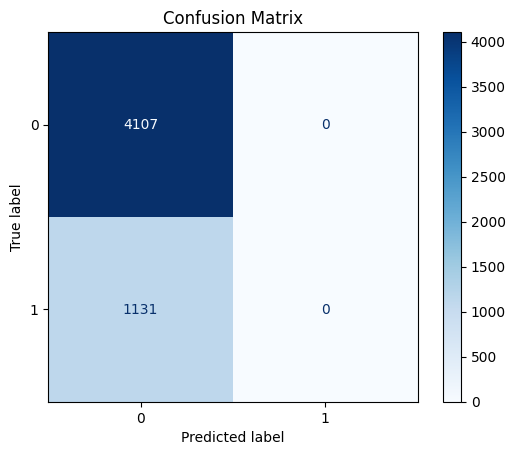

In [83]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=best_model.classes_)

plt.figure()
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()